# Praktikum 3 - Regresi dengan Keras (Prediksi Harga Rumah)

Notebook ini berisi dua bagian:

1. **Regresi sederhana** pada data dummy (luas vs harga) dan **Tugas 4**: mengubah
   *learning rate* serta membandingkan loss.
2. **Regresi harga rumah dengan data Boston** menggunakan MLP Keras (64-32-1).

> Catatan: `sklearn.datasets.load_boston` sudah dihapus sejak scikit-learn 1.2.
> Dataset Boston asli (506 data, 13 fitur) digunakan melalui file `boston.csv`.

## Bagian A - Regresi Sederhana (Data Dummy)

### Langkah 1 - Import Library

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf

%matplotlib inline
RANDOM_STATE = 42
SEEDS = [42, 7, 123]

tf.get_logger().setLevel('ERROR')
print('TensorFlow:', tf.__version__)

TensorFlow: 2.20.0


### Langkah 2 - Membuat Dataset

In [2]:
# Contoh dataset (data dummy)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

data

,luas,harga
0,50,500
1,60,600
2,70,700
3,80,800
4,90,900


### Langkah 3 - Split dan Normalisasi

Split dilakukan **sebelum** normalisasi, kemudian scaler di-fit hanya pada data latih
agar tidak terjadi kebocoran data (*data leakage*). Scaler X dan y dipisah agar prediksi
dapat dikembalikan ke satuan harga asli.

In [3]:
X_raw = data[['luas']].values
y_raw = data[['harga']].values

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=RANDOM_STATE
)

x_scaler = StandardScaler().fit(X_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

X_train = x_scaler.transform(X_train_raw)
X_test = x_scaler.transform(X_test_raw)
y_train = y_scaler.transform(y_train_raw)
y_test = y_scaler.transform(y_test_raw)

print('Data latih :', X_train.shape)
print('Data uji   :', X_test.shape)
print('Data uji (luas, harga):', X_test_raw.ravel(), y_test_raw.ravel())

Data latih : (4, 1)
Data uji   : (1, 1)
Data uji (luas, harga): [60] [600]


### Langkah 4 - Model Regresi (Konfigurasi Awal, lr = 0.001)

In [4]:
def build_simple_model(input_dim=1, hidden_units=10, learning_rate=0.001, seed=RANDOM_STATE):
    tf.keras.utils.set_random_seed(seed)

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(hidden_units, activation='relu'),
        tf.keras.layers.Dense(1)
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mse'
    )
    return model


def train_simple_model(learning_rate=0.001, seed=RANDOM_STATE, epochs=100):
    model = build_simple_model(learning_rate=learning_rate, seed=seed)
    history = model.fit(X_train, y_train, epochs=epochs, batch_size=32, verbose=0)

    train_loss = model.evaluate(X_train, y_train, verbose=0)
    test_loss = model.evaluate(X_test, y_test, verbose=0)

    pred_scaled = model.predict(X_test, verbose=0)
    pred_price = y_scaler.inverse_transform(pred_scaled)

    return model, history, train_loss, test_loss, pred_price

In [5]:
model_awal, history_awal, train_loss_awal, test_loss_awal, pred_awal = train_simple_model(
    learning_rate=0.001, seed=RANDOM_STATE
)

print('Prediksi harga (asli):', pred_awal.ravel())
print('Harga aktual           :', y_test_raw.ravel())
print(f'Train MSE              : {train_loss_awal:.6f}')
print(f'Test MSE               : {test_loss_awal:.6f}')

Prediksi harga (asli): [727.3297]
Harga aktual           : [600]
Train MSE              : 0.707120
Test MSE               : 0.741159


In [6]:
model_awal.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95 (384.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 64 (260.00 B)

## Tugas 4 - Perbandingan Learning Rate (Data Dummy)

Learning rate yang diuji: **0.001** (default), **0.01**, dan **0.1**.
Arsitektur, jumlah epoch (100), batch size, dan seed dibuat sama. Setiap learning rate
diuji dengan 3 seed untuk melihat rata-rata dan variasi loss.

In [7]:
learning_rates = [0.001, 0.01, 0.1]
rows_lr = []
histories_lr = {lr: [] for lr in learning_rates}

for lr in learning_rates:
    for seed in SEEDS:
        _, hist, tr_loss, te_loss, pred = train_simple_model(
            learning_rate=lr, seed=seed, epochs=100
        )
        rows_lr.append({
            'Learning Rate': lr,
            'Seed': seed,
            'Train MSE': tr_loss,
            'Test MSE': te_loss,
            'Prediksi Harga': pred.ravel()[0],
        })
        histories_lr[lr].append(hist.history['loss'])

df_lr = pd.DataFrame(rows_lr)
df_lr

,Learning Rate,Seed,Train MSE,Test MSE,Prediksi Harga
0,0.001,42,0.707120,0.741159,727.329712
1,0.001,7,0.626700,0.461970,700.526611
2,0.001,123,0.228645,0.140627,655.463745
3,0.010,42,0.002651,0.011052,584.451294
4,0.010,7,0.003542,0.028984,574.820007
5,0.010,123,0.001024,0.047973,567.605530
6,0.100,42,0.000006,0.009332,585.712402
7,0.100,7,0.000076,0.052600,566.079041
8,0.100,123,0.000020,0.056368,564.885193


In [8]:
summary_rows = []
for lr in learning_rates:
    sub = df_lr[df_lr['Learning Rate'] == lr]
    summary_rows.append({
        'Learning Rate': lr,
        'Train MSE': f"{sub['Train MSE'].mean():.6f} ± {sub['Train MSE'].std():.6f}",
        'Test MSE': f"{sub['Test MSE'].mean():.6f} ± {sub['Test MSE'].std():.6f}",
        'Prediksi Harga': f"{sub['Prediksi Harga'].mean():.2f} ± {sub['Prediksi Harga'].std():.2f}",
    })

summary_lr = pd.DataFrame(summary_rows)
summary_lr

,Learning Rate,Train MSE,Test MSE,Prediksi Harga
0,0.001,0.520822 ± 0.256207,0.447919 ± 0.300512,694.44 ± 36.32
1,0.010,0.002405 ± 0.001277,0.029336 ± 0.018463,575.63 ± 8.45
2,0.100,0.000034 ± 0.000037,0.039433 ± 0.026137,572.23 ± 11.70


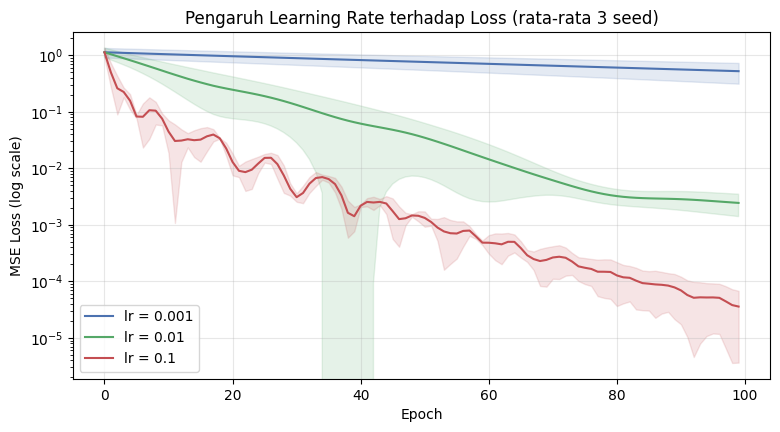

In [9]:
# Kurva loss rata-rata untuk setiap learning rate
plt.figure(figsize=(9, 4.5))

for lr, color in zip(learning_rates, ['#4c72b0', '#55a868', '#c44e52']):
    hist = np.array(histories_lr[lr])
    mean = hist.mean(axis=0)
    std = hist.std(axis=0)
    epoch_axis = np.arange(mean.shape[0])

    plt.plot(epoch_axis, mean, label=f'lr = {lr}', color=color)
    plt.fill_between(epoch_axis, mean - std, mean + std, alpha=0.15, color=color)

plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss (log scale)')
plt.title('Pengaruh Learning Rate terhadap Loss (rata-rata 3 seed)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

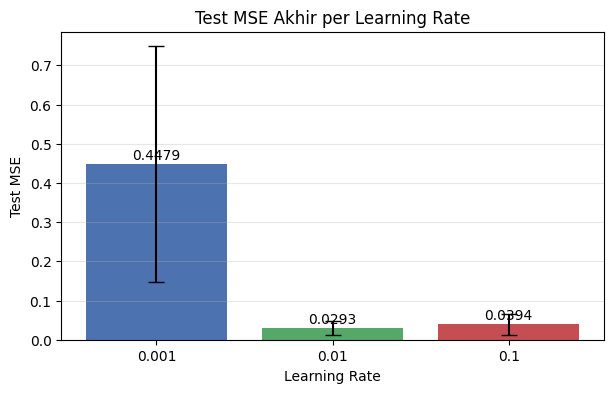

In [10]:
# Perbandingan Test MSE akhir
means = df_lr.groupby('Learning Rate')['Test MSE'].mean()
stds = df_lr.groupby('Learning Rate')['Test MSE'].std()

plt.figure(figsize=(7, 4))
bars = plt.bar([str(lr) for lr in learning_rates], means.values, yerr=stds.values,
               capsize=6, color=['#4c72b0', '#55a868', '#c44e52'])

for bar, value in zip(bars, means.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
             f'{value:.4f}', ha='center', va='bottom')

plt.xlabel('Learning Rate')
plt.ylabel('Test MSE')
plt.title('Test MSE Akhir per Learning Rate')
plt.grid(axis='y', alpha=0.3)
plt.show()

**Pembahasan Tugas 4 (data dummy):**
- Learning rate terlalu kecil (0.001) membuat konvergensi lebih lambat: setelah 100 epoch
  train MSE masih sekitar 0.52 dan prediksi harga masih jauh dari nilai aktual.
- Learning rate 0.01 dan 0.1 mempercepat konvergensi secara drastis: train MSE turun
  menjadi sekitar 0.002 (lr = 0.01) dan 0.00003 (lr = 0.1) pada jumlah epoch yang sama.
- Pada data uji, lr = 0.01 memberi MSE rata-rata terkecil (sekitar 0.029), sedangkan
  lr = 0.1 memberi train loss terkecil tetapi test MSE sedikit lebih tinggi (sekitar 0.039)
  karena model sangat cepat menyesuaikan 4 data latih.
- Learning rate yang terlalu besar berisiko tidak stabil atau overfitting, sehingga nilai
  optimal perlu dicari melalui eksperimen.

## Bagian B - Prediksi Harga Rumah dengan Data Boston

Dataset Boston berisi 506 data dengan 13 fitur (crim, zn, indus, chas, nox, rm, age,
dis, rad, tax, ptratio, b, lstat) dan target `medv` (harga rumah dalam ribuan dolar).

### Langkah 1 - Load Dataset Boston

In [11]:
boston = pd.read_csv('boston.csv')

print('Shape dataset:', boston.shape)
boston.head()

Shape dataset: (506, 14)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [12]:
boston.describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
crim,3.613524,8.601545,0.00632,88.9762
zn,11.363636,23.322453,0.00000,100.0000
indus,11.136779,6.860353,0.46000,27.7400
chas,0.069170,0.253994,0.00000,1.0000
nox,0.554695,0.115878,0.38500,0.8710
rm,6.284634,0.702617,3.56100,8.7800
age,68.574901,28.148861,2.90000,100.0000
dis,3.795043,2.105710,1.12960,12.1265
rad,9.549407,8.707259,1.00000,24.0000
tax,408.237154,168.537116,187.00000,711.0000


### Langkah 2 - Preprocess

In [13]:
X_boston = boston.drop(columns='medv').values
y_boston = boston['medv'].values

X_train_b, X_val_b, y_train_b, y_val_b = train_test_split(
    X_boston, y_boston, test_size=0.2, random_state=RANDOM_STATE
)

# Scaling di-fit pada data latih saja
scaler_boston = StandardScaler().fit(X_train_b)
X_train_b = scaler_boston.transform(X_train_b)
X_val_b = scaler_boston.transform(X_val_b)

print('Data latih :', X_train_b.shape)
print('Data validasi:', X_val_b.shape)

Data latih : (404, 13)
Data validasi: (102, 13)


### Langkah 3 - Bangun, Kompilasi, dan Latih Model

In [14]:
def train_boston_model(learning_rate=0.001, seed=RANDOM_STATE, epochs=200, batch_size=32):
    tf.keras.utils.set_random_seed(seed)

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(X_train_b.shape[1],)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1)
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae']
    )

    history = model.fit(
        X_train_b, y_train_b,
        validation_data=(X_val_b, y_val_b),
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )

    val_loss, val_mae = model.evaluate(X_val_b, y_val_b, verbose=0)
    pred = model.predict(X_val_b, verbose=0).ravel()
    rmse = np.sqrt(mean_squared_error(y_val_b, pred))
    r2 = r2_score(y_val_b, pred)

    metrics = {
        'Val Loss (MSE)': val_loss,
        'Val MAE': val_mae,
        'RMSE': rmse,
        'R2': r2,
    }
    return model, history, metrics, pred

In [15]:
model_boston, history_boston, metrics_boston, pred_boston = train_boston_model(
    learning_rate=0.001, seed=RANDOM_STATE, epochs=200, batch_size=32
)

model_boston.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,029 (35.27 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,020 (23.52 KB)

### Langkah 4 - Plot Loss dan MAE

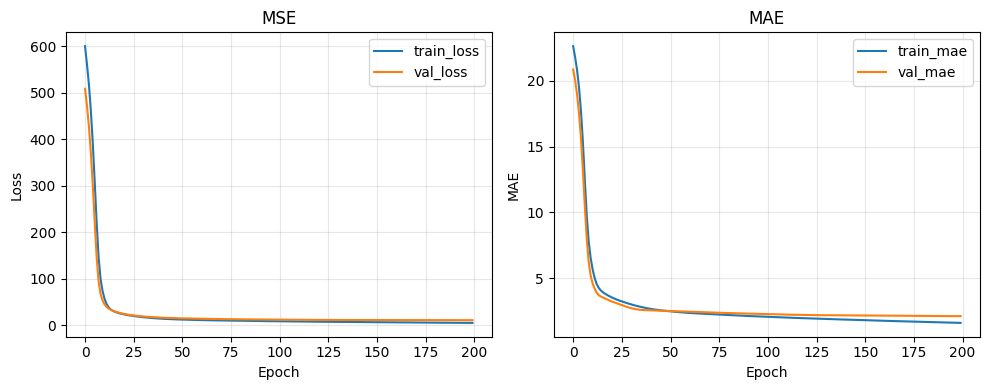

In [16]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_boston.history['loss'], label='train_loss')
plt.plot(history_boston.history['val_loss'], label='val_loss')
plt.legend()
plt.title('MSE')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_boston.history['mae'], label='train_mae')
plt.plot(history_boston.history['val_mae'], label='val_mae')
plt.legend()
plt.title('MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Langkah 5 - Evaluasi

In [17]:
print('RMSE:', np.sqrt(mean_squared_error(y_val_b, pred_boston)))
print(f"RMSE : {metrics_boston['RMSE']:.4f}")
print(f"MAE  : {metrics_boston['Val MAE']:.4f}")
print(f"R2   : {metrics_boston['R2']:.4f}")

# Bandingkan beberapa prediksi dengan nilai aktual
comparison = pd.DataFrame({
    'Aktual': y_val_b,
    'Prediksi': pred_boston,
    'Selisih': pred_boston - y_val_b,
}).round(2)

comparison.head(10)

RMSE: 3.2376530232306258
RMSE : 3.2377
MAE  : 2.1001
R2   : 0.8571


,Aktual,Prediksi,Selisih
0,23.6,26.469999,2.87
1,32.4,34.680000,2.28
2,13.6,15.450000,1.85
3,22.8,23.719999,0.92
4,16.1,15.990000,-0.11
5,20.0,19.040001,-0.96
6,17.8,17.190001,-0.61
7,14.0,14.930000,0.93
8,19.6,24.620001,5.02
9,16.8,18.030001,1.23


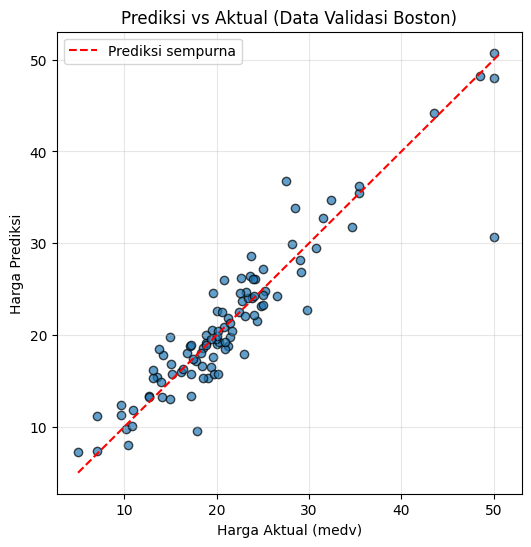

In [18]:
# Scatter plot prediksi vs aktual
plt.figure(figsize=(6, 6))
plt.scatter(y_val_b, pred_boston, alpha=0.7, edgecolor='k')

lims = [min(y_val_b.min(), pred_boston.min()), max(y_val_b.max(), pred_boston.max())]
plt.plot(lims, lims, 'r--', label='Prediksi sempurna')

plt.xlabel('Harga Aktual (medv)')
plt.ylabel('Harga Prediksi')
plt.title('Prediksi vs Aktual (Data Validasi Boston)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Tugas 4 (Penerapan pada Data Boston) - Perbandingan Learning Rate

Model yang sama dilatih dengan learning rate **0.0001**, **0.001**, dan **0.01**
menggunakan seed yang sama. Metrik yang dibandingkan adalah validation loss (MSE),
MAE, dan RMSE.

In [19]:
boston_lrs = [0.0001, 0.001, 0.01]

rows_boston = [{
    'Learning Rate': 0.001,
    'Val Loss (MSE)': metrics_boston['Val Loss (MSE)'],
    'Val MAE': metrics_boston['Val MAE'],
    'RMSE': metrics_boston['RMSE'],
    'R2': metrics_boston['R2'],
}]

histories_boston_lr = {0.001: history_boston.history}

for lr in [0.0001, 0.01]:
    _, hist, metrics, _ = train_boston_model(
        learning_rate=lr, seed=RANDOM_STATE, epochs=200, batch_size=32
    )
    rows_boston.append({
        'Learning Rate': lr,
        'Val Loss (MSE)': metrics['Val Loss (MSE)'],
        'Val MAE': metrics['Val MAE'],
        'RMSE': metrics['RMSE'],
        'R2': metrics['R2'],
    })
    histories_boston_lr[lr] = hist.history

df_boston_lr = pd.DataFrame(rows_boston).sort_values('Learning Rate').reset_index(drop=True)
df_boston_lr

,Learning Rate,Val Loss (MSE),Val MAE,RMSE,R2
0,0.0001,24.136250,3.207353,4.912866,0.670871
1,0.0010,10.482397,2.100109,3.237653,0.857059
2,0.0100,10.616716,2.288304,3.258330,0.855227


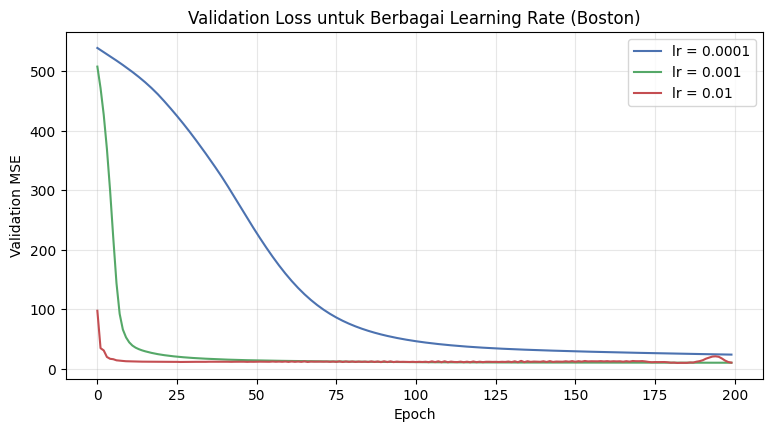

In [20]:
# Kurva validation loss untuk setiap learning rate
plt.figure(figsize=(9, 4.5))

for lr, color in zip(sorted(histories_boston_lr), ['#4c72b0', '#55a868', '#c44e52']):
    plt.plot(histories_boston_lr[lr]['val_loss'], label=f'lr = {lr}', color=color)

plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.title('Validation Loss untuk Berbagai Learning Rate (Boston)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Analisis

**Data dummy (Tugas 4):**
- Learning rate yang lebih besar (0.01 dan 0.1) membuat model konvergen lebih cepat
  sehingga loss akhir jauh lebih kecil daripada lr = 0.001 pada 100 epoch.
- Namun learning rate yang terlalu besar dapat membuat training tidak stabil pada
  masalah yang lebih kompleks, sehingga perlu dipilih secara hati-hati.

**Data Boston:**
- Model MLP 64-32-1 dengan lr = 0.001 mencapai RMSE sekitar 3.2 (ribuan dolar) dan
  R² sekitar 0.86 pada data validasi.
- lr = 0.0001 terlalu kecil: setelah 200 epoch model belum konvergen (loss validasi
  masih tinggi).
- lr = 0.01 memberikan hasil yang kompetitif, tetapi pada percobaan ini lr = 0.001
  memberikan validation loss terbaik.
- Kurva train dan validation loss yang berdekatan menunjukkan model tidak mengalami
  overfitting yang berarti.

## Kesimpulan

In [21]:
print('=== Tugas 4: Learning Rate pada Data Dummy ===')
print(summary_lr.to_string(index=False))

print('\n=== Data Boston: Learning Rate vs Performansi Validasi ===')
print(df_boston_lr.round(4).to_string(index=False))

=== Tugas 4: Learning Rate pada Data Dummy ===
 Learning Rate           Train MSE            Test MSE Prediksi Harga
         0.001 0.520822 ± 0.256207 0.447919 ± 0.300512 694.44 ± 36.32
         0.010 0.002405 ± 0.001277 0.029336 ± 0.018463  575.63 ± 8.45
         0.100 0.000034 ± 0.000037 0.039433 ± 0.026137 572.23 ± 11.70

=== Data Boston: Learning Rate vs Performansi Validasi ===
 Learning Rate  Val Loss (MSE)  Val MAE   RMSE     R2
        0.0001         24.1362   3.2074 4.9129 0.6709
        0.0010         10.4824   2.1001 3.2377 0.8571
        0.0100         10.6167   2.2883 3.2583 0.8552
